# Stage 0 — Baseline correction: reproducing the verdict

**What this notebook establishes.** Every number quoted in
[`docs/stage0_findings.md`](../docs/stage0_findings.md) can be reproduced here, and the
reasoning behind each can be inspected step by step.

The question Stage 0 asked: the pipeline inherited `airpls_lambda = 100` from Lita et al.
(the "Apollo" work), tuned by eye. Is that defensible, and if not, what replaces it?

The plan proposed selecting λ per spectrum by generalised cross-validation. **The study
rejected that proposal.** This notebook reproduces why, and why IARPLS won instead.

### How to run

Run top to bottom. Live cells use small sample sizes so the whole notebook finishes in
about a minute; the headline tables are loaded from the committed full study
(`results/stage0_baseline/`, n=40 per cell) so they match the findings document exactly.

To regenerate the full study from scratch (several minutes):

```bash
python scripts/stage0_baseline_study.py --n-spectra 40 --out-dir results/stage0_baseline
```

Everything is seeded; reruns are bit-identical.

In [1]:
import sys, os, warnings
from pathlib import Path

# Work from the repository root regardless of where Jupyter was started.
ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "scripts"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

from src.preprocessing.baseline import (
    DEFAULT_LAMBDA_GRID, RAMAN_REFERENCE_BANDS, IARPLS_LAMBDA, IARPLS_VALID_FROM_CM1,
    airpls, correct, correct_iarpls, difference_penalty_banded, gcv_curve, lcurve, whittaker,
)
from stage0_baseline_study import (
    FLUORESCENCE_LEVELS, SPECTRAL_REGIONS, load_wavenumbers,
    peak_heights, run_iarpls, synthetic_baseline, synthetic_signal,
)

RESULTS = ROOT / "results" / "stage0_baseline"
HAVE_FULL = (RESULTS / "stage0_synthetic_raw.csv").exists()
HAVE_RAW  = (ROOT / "data" / "raw").is_dir()

wn = load_wavenumbers()
print(f"root            : {ROOT}")
print(f"wavenumbers     : {wn.size} points, {wn.min():.1f}-{wn.max():.1f} cm-1 "
      f"({np.mean(np.diff(wn)):.2f} cm-1/point)")
print(f"full study CSVs : {'found' if HAVE_FULL else 'MISSING - run the script above'}")
print(f"raw data cubes  : {'found' if HAVE_RAW else 'absent - real-data cells will be skipped'}")
print(f"IARPLS defaults : lambda={IARPLS_LAMBDA:g}, valid from {IARPLS_VALID_FROM_CM1:g} cm-1")

root            : C:\Users\Andrei\incdsb\glioma-synthetic-data
wavenumbers     : 1738 points, 50.0-3399.8 cm-1 (1.93 cm-1/point)
full study CSVs : found
raw data cubes  : found
IARPLS defaults : lambda=10000, valid from 300 cm-1


---
## 1. The machinery is correct

Before trusting any comparison, check the new numerical code against dense reference
implementations. These are the same assertions as `tests/test_baseline.py`, shown here so a
reviewer can see the error magnitudes rather than just a passing test.

The solver was rewritten from the old `scipy.sparse.linalg.spsolve` to
`scipy.linalg.solveh_banded`: the system `W + λ·DᵀD` is symmetric, positive definite and
banded, so the banded Cholesky is roughly two orders of magnitude faster. That speedup is
what makes a per-spectrum grid search affordable at all.

In [2]:
def banded_to_dense(ab):
    order, m = ab.shape[0] - 1, ab.shape[1]
    A = np.zeros((m, m))
    for k in range(order + 1):
        idx = np.arange(m - k)
        A[idx, idx + k] = A[idx + k, idx] = ab[order - k, k:]
    return A

# (a) banded D'D == dense D'D
for order in (1, 2, 3):
    m = 60
    dense = np.diff(np.eye(m), order, axis=0).T @ np.diff(np.eye(m), order, axis=0)
    err = np.abs(banded_to_dense(np.array(difference_penalty_banded(m, order))) - dense).max()
    print(f"  order {order}: max |banded - dense| = {err:.2e}")

# (b) banded solve == dense solve
rng = np.random.default_rng(1)
m = 120
y = rng.normal(size=m) + np.linspace(0, 5, m)
w = rng.uniform(0, 1, m)
lam = 37.0
got = whittaker(y, w, lam, difference_penalty_banded(m, 2))
A = np.diag(w) + lam * (np.diff(np.eye(m), 2, axis=0).T @ np.diff(np.eye(m), 2, axis=0))
A += np.eye(m) * 1e-9 * max(np.diag(A).max(), 1.0)
print(f"  banded vs dense solve: max abs diff = {np.abs(got - np.linalg.solve(A, w * y)).max():.2e}")

# (c) Hutchinson trace estimator vs exact trace (this gates the GCV score)
from src.preprocessing.baseline import _assemble, _trace_hat
w = np.random.default_rng(2).uniform(0.2, 1.0, 150)
ab_dd = difference_penalty_banded(150, 2)
exact = np.trace(np.linalg.solve(banded_to_dense(_assemble(ab_dd, w, 25.0)), np.diag(w)))
est = _trace_hat(ab_dd, w, 25.0, n_probe=512, seed=0)
print(f"  tr(H): exact = {exact:.3f}, Hutchinson = {est:.3f}  ({abs(est-exact)/exact:.2%} rel. error)")

  order 1: max |banded - dense| = 0.00e+00
  order 2: max |banded - dense| = 0.00e+00
  order 3: max |banded - dense| = 0.00e+00
  banded vs dense solve: max abs diff = 1.66e-13
  tr(H): exact = 22.075, Hutchinson = 22.178  (0.46% rel. error)


---
## 2. One spectrum, seen directly

A synthetic Raman-like signal (14 Gaussian bands at real positions) on a known baseline at
8× the signal amplitude, with noise matched to the measured SNR of 235.

Watch the blue curve: **airPLS at λ=100 climbs into the bands.** Where the true baseline
(red dashed) passes underneath a peak, λ=100 rides up over it — and it does this more for
wide bands than narrow ones, which is the whole finding.

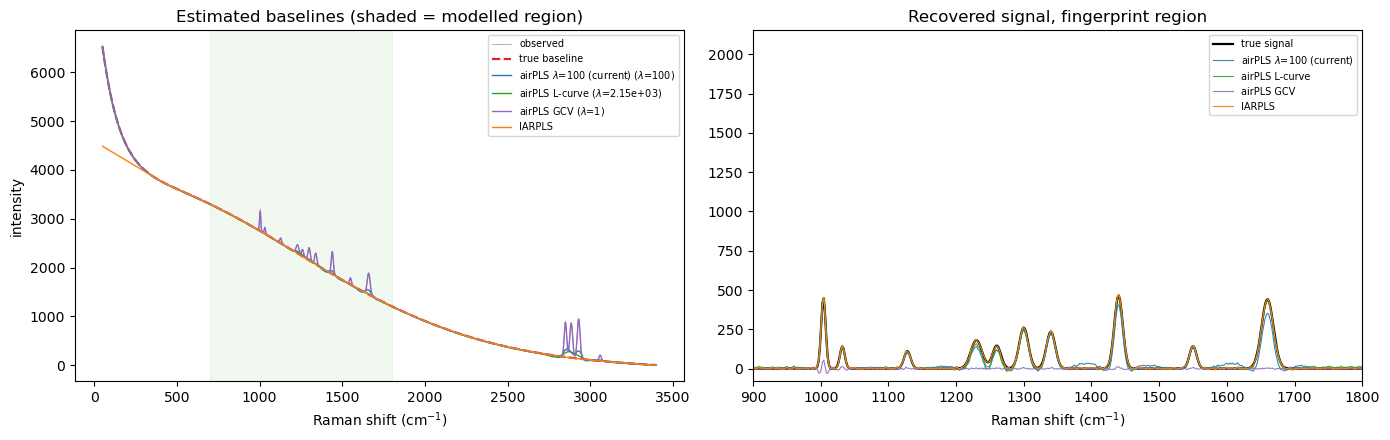

recovered / true peak height, this spectrum:
                                phenylalanine_1004  ch2_deformation_1440  amide_I_1660  ch_stretch_2930
airPLS $\lambda$=100 (current)               0.994                 0.872         0.797            0.806
airPLS L-curve                               1.009                 0.998         0.970            0.928
airPLS GCV                                   0.122                 0.023         0.008            0.009
IARPLS                                       1.016                 1.015         1.000            1.002


In [3]:
rng = np.random.default_rng(42)
sig = synthetic_signal(wn, rng)
scale = np.ptp(sig)
base = synthetic_baseline(wn, rng, amplitude=8 * scale)
obs = sig + base + rng.normal(0, scale / 235.0, wn.size)

fits = {
    "airPLS $\\lambda$=100 (current)": correct(obs, lam=100.0, endpoint="legacy", clip_negative=False),
    "airPLS L-curve":                  correct(obs, method="lcurve", clip_negative=False),
    "airPLS GCV":                      correct(obs, method="gcv", clip_negative=False),
}
ci, bi = run_iarpls(obs, wn, lam=IARPLS_LAMBDA)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ax = axes[0]
ax.plot(wn, obs, lw=0.6, color="0.65", label="observed")
ax.plot(wn, base, lw=1.6, color="C3", ls="--", label="true baseline")
for (name, r), col in zip(fits.items(), ["C0", "C2", "C4"]):
    ax.plot(wn, r["baseline"], lw=1.0, color=col, label=f"{name} ($\\lambda$={r['lambda']:.3g})")
ax.plot(wn, bi, lw=1.0, color="C1", label="IARPLS")
ax.axvspan(700, 1800, color="C2", alpha=0.07)
ax.set_xlabel("Raman shift (cm$^{-1}$)"); ax.set_ylabel("intensity")
ax.set_title("Estimated baselines (shaded = modelled region)"); ax.legend(fontsize=7)

ax = axes[1]
ax.plot(wn, sig, lw=1.6, color="k", label="true signal")
for (name, r), col in zip(fits.items(), ["C0", "C2", "C4"]):
    ax.plot(wn, r["corrected"], lw=0.8, color=col, alpha=0.9, label=name)
ax.plot(wn, ci, lw=0.8, color="C1", label="IARPLS")
ax.set_xlim(900, 1800); ax.set_ylim(-80, None)
ax.set_xlabel("Raman shift (cm$^{-1}$)")
ax.set_title("Recovered signal, fingerprint region"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

ht = peak_heights(wn, sig)
rows = {n: {k: peak_heights(wn, r["corrected"])[k] / ht[k] for k in ht} for n, r in fits.items()}
rows["IARPLS"] = {k: peak_heights(wn, ci)[k] / ht[k] for k in ht}
print("recovered / true peak height, this spectrum:")
print(pd.DataFrame(rows).T.round(3).to_string())

---
## 3. Why GCV fails

GCV pins at the bottom of the λ grid and the baseline swallows the signal. This is not a
grid-range problem — extending the grid downward makes it worse.

**The reason is structural.** GCV assumes the residual is i.i.d. noise. At convergence
airPLS gives the peak regions weight ≈ 0, so the points GCV actually sees are the
baseline-like ones — but the residual *there* is still structured Raman signal, not noise.
GCV reads that structure as "the fit is too stiff" and drives λ to the floor.

The L-curve criterion, on the same grid and the same weights, never pins.

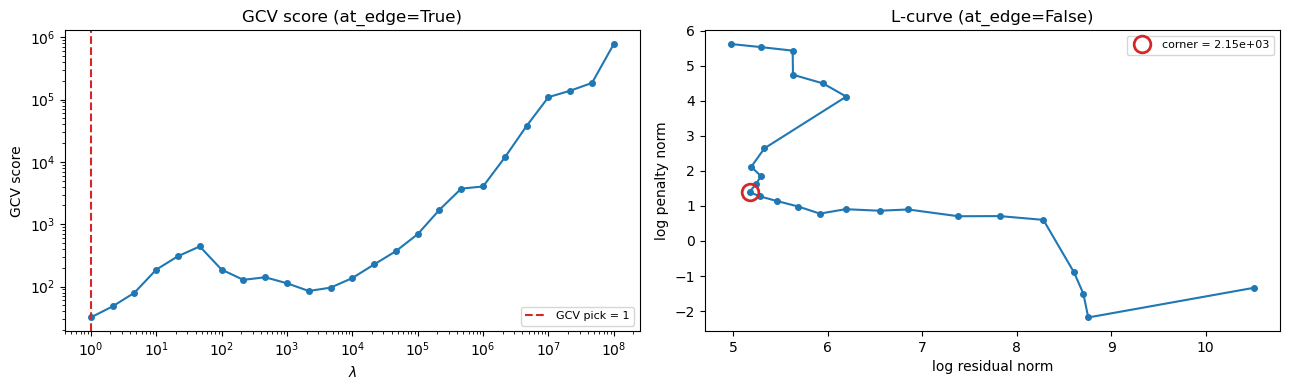

GCV     : pinned at a grid edge in 100% of spectra, median lambda 1
L-curve : pinned at a grid edge in 0% of spectra, median lambda 5.5e+04
(grid spans 1 to 1e+08)


In [4]:
g = gcv_curve(obs); l = lcurve(obs)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.loglog(g["grid"], g["scores"], "o-", ms=4)
ax.axvline(g["lambda"], color="C3", ls="--", label=f"GCV pick = {g['lambda']:.3g}")
ax.set_xlabel("$\\lambda$"); ax.set_ylabel("GCV score"); ax.legend(fontsize=8)
ax.set_title(f"GCV score (at_edge={g['at_edge']})")
ax = axes[1]
ax.plot(l["rho"], l["eta"], "o-", ms=4)
ax.plot(l["rho"][l["index"]], l["eta"][l["index"]], "o", ms=12, mfc="none", mec="C3", mew=2,
        label=f"corner = {l['lambda']:.3g}")
ax.set_xlabel("log residual norm"); ax.set_ylabel("log penalty norm"); ax.legend(fontsize=8)
ax.set_title(f"L-curve (at_edge={l['at_edge']})")
plt.tight_layout(); plt.show()

# Edge-pinning rate over a fresh sample.
edge_g, edge_l, lam_g, lam_l = [], [], [], []
for k in range(12):
    r = np.random.default_rng(300 + k)
    s = synthetic_signal(wn, r); sc = np.ptp(s)
    o = s + synthetic_baseline(wn, r, amplitude=8 * sc) + r.normal(0, sc / 235.0, wn.size)
    a, b = gcv_curve(o, n_probe=32), lcurve(o)
    edge_g.append(a["at_edge"]); lam_g.append(a["lambda"])
    edge_l.append(b["at_edge"]); lam_l.append(b["lambda"])
print(f"GCV     : pinned at a grid edge in {np.mean(edge_g):.0%} of spectra, median lambda {np.median(lam_g):.3g}")
print(f"L-curve : pinned at a grid edge in {np.mean(edge_l):.0%} of spectra, median lambda {np.median(lam_l):.3g}")
print(f"(grid spans {DEFAULT_LAMBDA_GRID.min():g} to {DEFAULT_LAMBDA_GRID.max():g})")

---
## 4. The decisive comparison: IARPLS vs the *best possible* airPLS λ

This is the cell that settles the stage. Rather than compare IARPLS against some chosen λ,
search the whole grid for the λ that minimises the true error against known ground truth —
an oracle no selector could beat — and compare IARPLS to that.

IARPLS wins against the oracle. So this is a **better algorithm**, not a better-tuned one,
and no amount of λ selection for airPLS closes the gap.

In [5]:
m_fp = (wn >= 700) & (wn < 1800)
def fp_nrmse(corrected, truth, sc):
    return float(np.sqrt(np.mean((corrected[m_fp] - truth[m_fp]) ** 2)) / sc)

oracle_rows = []
for level, amp in FLUORESCENCE_LEVELS.items():
    per_lam, iar = [], []
    for k in range(5):
        r = np.random.default_rng(700 + k)
        s = synthetic_signal(wn, r); sc = np.ptp(s)
        o = s + synthetic_baseline(wn, r, amplitude=amp * sc) + r.normal(0, sc / 235.0, wn.size)
        per_lam.append([fp_nrmse(correct(o, lam=lm, clip_negative=False)["corrected"], s, sc)
                        for lm in DEFAULT_LAMBDA_GRID])
        iar.append(fp_nrmse(run_iarpls(o, wn)[0], s, sc))
    curve = np.median(np.array(per_lam), axis=0)
    j = int(np.argmin(curve))
    oracle_rows.append({
        "level": level,
        "airPLS lambda=100": float(curve[np.argmin(np.abs(DEFAULT_LAMBDA_GRID - 100))]),
        "airPLS ORACLE lambda": float(DEFAULT_LAMBDA_GRID[j]),
        "airPLS oracle NRMSE": float(curve[j]),
        "IARPLS NRMSE": float(np.median(iar)),
    })
t = pd.DataFrame(oracle_rows).set_index("level")
t["IARPLS better by"] = (t["airPLS oracle NRMSE"] / t["IARPLS NRMSE"]).round(1).astype(str) + "x"
print("Fingerprint NRMSE (700-1800 cm-1); lower is better\n")
print(t.round(4).to_string())

Fingerprint NRMSE (700-1800 cm-1); lower is better

        airPLS lambda=100  airPLS ORACLE lambda  airPLS oracle NRMSE  IARPLS NRMSE IARPLS better by
level                                                                                              
low                0.0219            21544.3469               0.0069        0.0048             1.5x
medium             0.0430            46415.8883               0.0120        0.0048             2.5x
high               0.0883            21544.3469               0.0141        0.0049             2.9x


---
## 5. λ is *inert* for IARPLS

The project rule is that no parameter may be fitted across the dataset. IARPLS satisfies it
in a stronger way than a selector would: over λ ∈ [10², 10⁴] the result does not change, so
the constant carries no information at all. It is documented, not tuned.

It degrades only above 10⁵, and only under heavy fluorescence.

In [6]:
lams = [1e2, 1e3, 1e4, 1e5, 1e6]
rows = []
for lam in lams:
    row = {"lambda": lam}
    for level, amp in FLUORESCENCE_LEVELS.items():
        errs = []
        for k in range(5):
            r = np.random.default_rng(1000 + k)
            s = synthetic_signal(wn, r); sc = np.ptp(s)
            o = s + synthetic_baseline(wn, r, amplitude=amp * sc) + r.normal(0, sc / 235.0, wn.size)
            errs.append(fp_nrmse(run_iarpls(o, wn, lam=lam)[0], s, sc))
        row[level] = float(np.median(errs))
    rows.append(row)
sens = pd.DataFrame(rows).set_index("lambda")
print("Fingerprint NRMSE vs IARPLS lambda\n")
print(sens.round(4).to_string())
print(f"\nSpread over 1e2..1e4: {np.ptp(sens.loc[[1e2,1e3,1e4]].values):.5f}  (i.e. inert)")

Fingerprint NRMSE vs IARPLS lambda

              low  medium    high
lambda                           
100.0      0.0052  0.0052  0.0052
1000.0     0.0048  0.0048  0.0048
10000.0    0.0046  0.0046  0.0046
100000.0   0.0046  0.0046  0.0052
1000000.0  0.0046  0.0055  1.3944

Spread over 1e2..1e4: 0.00066  (i.e. inert)


---
## 6. Purity — the invariant the whole project rests on

No spectrum's output may depend on what else is being processed. If this fails, preprocessing
becomes fold-dependent and the cross-validation guarantee leaks at the preprocessing layer.

Checked two ways: a spectrum alone vs inside a batch, and the same batch in reverse order.
Both must be **bit-identical**, not merely close.

In [7]:
specs = []
for k in range(5):
    r = np.random.default_rng(500 + k)
    s = synthetic_signal(wn, r); sc = np.ptp(s)
    specs.append(s + synthetic_baseline(wn, r, amplitude=(2 + 9 * k) * sc) + r.normal(0, sc / 235.0, wn.size))
specs = np.array(specs)

alone    = np.array([correct_iarpls(s, wn, clip_negative=False)["corrected"] for s in specs])
reversed_= np.array([correct_iarpls(s, wn, clip_negative=False)["corrected"] for s in specs[::-1]])[::-1]
import ramanspy as rp
batch = np.asarray(rp.preprocessing.baseline.IARPLS(lam=IARPLS_LAMBDA)
                   .apply(rp.SpectralContainer(specs, wn)).spectral_data)

print(f"alone vs reverse order : max |diff| = {np.abs(alone - reversed_).max():.3e}  "
      f"-> {'PASS' if np.array_equal(alone, reversed_) else 'FAIL'}")
print(f"alone vs batched       : max |diff| = {np.abs(alone - batch).max():.3e}  "
      f"-> {'PASS' if np.allclose(alone, batch, atol=0, rtol=0) else 'FAIL'}")

alone vs reverse order : max |diff| = 0.000e+00  -> PASS
alone vs batched       : max |diff| = 0.000e+00  -> PASS


---
## 7. Where IARPLS fails: the Rayleigh wing

IARPLS does not model the steep rise below ~300 cm⁻¹ (the notch-filter cutoff). Everything
below that is unusable and must be cropped — recorded in code as `IARPLS_VALID_FROM_CM1`.

This costs nothing in practice: that region is routinely discarded, and the pipeline's
existing 700–1800 cm⁻¹ crop already satisfies the constraint. But the export must not
silently ship it, which is why it is a named constant rather than a comment.

In [8]:
rows = []
for lo, hi, lab in [(0,200,"<200 (Rayleigh)"), (200,300,"200-300"), (300,500,"300-500"),
                    (500,700,"500-700"), (700,1800,"700-1800 (modelled)"), (2600,3100,"2600-3100 (CH)")]:
    m = (wn >= lo) & (wn < hi)
    rows.append({
        "region": lab,
        "IARPLS": float(np.sqrt(np.mean((ci[m] - sig[m])**2)) / scale),
        "airPLS lambda=100": float(np.sqrt(np.mean((fits["airPLS $\\lambda$=100 (current)"]["corrected"][m] - sig[m])**2)) / scale),
    })
print("NRMSE by spectral region\n")
print(pd.DataFrame(rows).set_index("region").round(4).to_string())
print(f"\nIARPLS_VALID_FROM_CM1 = {IARPLS_VALID_FROM_CM1:g} cm-1")

NRMSE by spectral region

                     IARPLS  airPLS lambda=100
region                                        
<200 (Rayleigh)      1.3206             0.0054
200-300              0.1883             0.0071
300-500              0.0131             0.0065
500-700              0.0044             0.0073
700-1800 (modelled)  0.0047             0.0269
2600-3100 (CH)       0.0047             0.0777

IARPLS_VALID_FROM_CM1 = 300 cm-1


---
## 8. The full study (n = 40 per cell)

The cells above use small samples so the notebook stays interactive. These are the committed
results of the full study — **the exact numbers quoted in the findings document**.

In [9]:
if not HAVE_FULL:
    print("Full-study CSVs not found. Run:")
    print("  python scripts/stage0_baseline_study.py --n-spectra 40 --out-dir results/stage0_baseline")
else:
    syn = pd.read_csv(RESULTS / "stage0_synthetic_raw.csv")
    inv = pd.read_csv(RESULTS / "stage0_invariance_raw.csv")

    print("=" * 78)
    print("PEAK-HEIGHT FIDELITY  (recovered / true; 1.000 is perfect)")
    print("=" * 78)
    cols = [f"peak_ratio_{b}" for b in RAMAN_REFERENCE_BANDS]
    pk = syn.groupby("method")[cols].median()
    pk.columns = [c.replace("peak_ratio_", "") for c in pk.columns]
    print(pk.round(3).to_string())
    print("\n-> airPLS lambda=100 keeps 90% of the NARROW 1004 band but only 57% of amide I.")
    print("   The distortion is differential, so it changes band RATIOS.\n")

    print("=" * 78)
    print("ERROR IN THE MODELLED REGION  (NRMSE, 700-1800 cm-1)")
    print("=" * 78)
    print(syn.pivot_table(index="method", columns="level", values="nrmse_fingerprint",
                          aggfunc="median").reindex(columns=["low","medium","high"]).round(4).to_string())

    print("\n" + "=" * 78)
    print("REAL-DATA INVARIANCE  (peak-height drift when fluorescence is added; 0 = invariant)")
    print("=" * 78)
    print(inv.pivot_table(index="method", columns="level", values="drift_mean",
                          aggfunc="median").reindex(columns=["low","medium","high"]).round(4).to_string())
    print("\n-> Under the current pipeline a spectrum's peak heights move 16-55% purely with")
    print("   fluorescence level. Fluorescence varies by slide and the CV groups by slide, so")
    print("   this is a confound aligned with the label. Under IARPLS it is ~0.1%.")

    print("\n" + "=" * 78)
    print("SELECTOR BEHAVIOUR")
    print("=" * 78)
    e = syn[syn.method.isin(["gcv","lcurve"])].groupby("method")["at_edge"].mean()
    for k, v in e.items():
        print(f"  {k:8s} pinned at a grid edge in {v:.1%} of spectra")

PEAK-HEIGHT FIDELITY  (recovered / true; 1.000 is perfect)
               phenylalanine_1004  ch2_deformation_1440  amide_I_1660  ch_stretch_2930
method                                                                                
gcv                         0.126                 0.025         0.017            0.011
iarpls                      1.003                 1.003         1.004            1.003
lcurve                      1.002                 0.997         0.987            0.927
legacy_lam100               0.900                 0.691         0.574            0.584
ref_lam100                  0.900                 0.691         0.574            0.584

-> airPLS lambda=100 keeps 90% of the NARROW 1004 band but only 57% of amide I.
   The distortion is differential, so it changes band RATIOS.

ERROR IN THE MODELLED REGION  (NRMSE, 700-1800 cm-1)
level             low  medium    high
method                               
gcv            0.0476  0.1178  0.1134
iarpls         0.0048

### The study figure

Panel (a) shows the estimated baselines; (b) peak-height fidelity; (c) error in the modelled
region by fluorescence level; (d) the λ-inertness sweep.

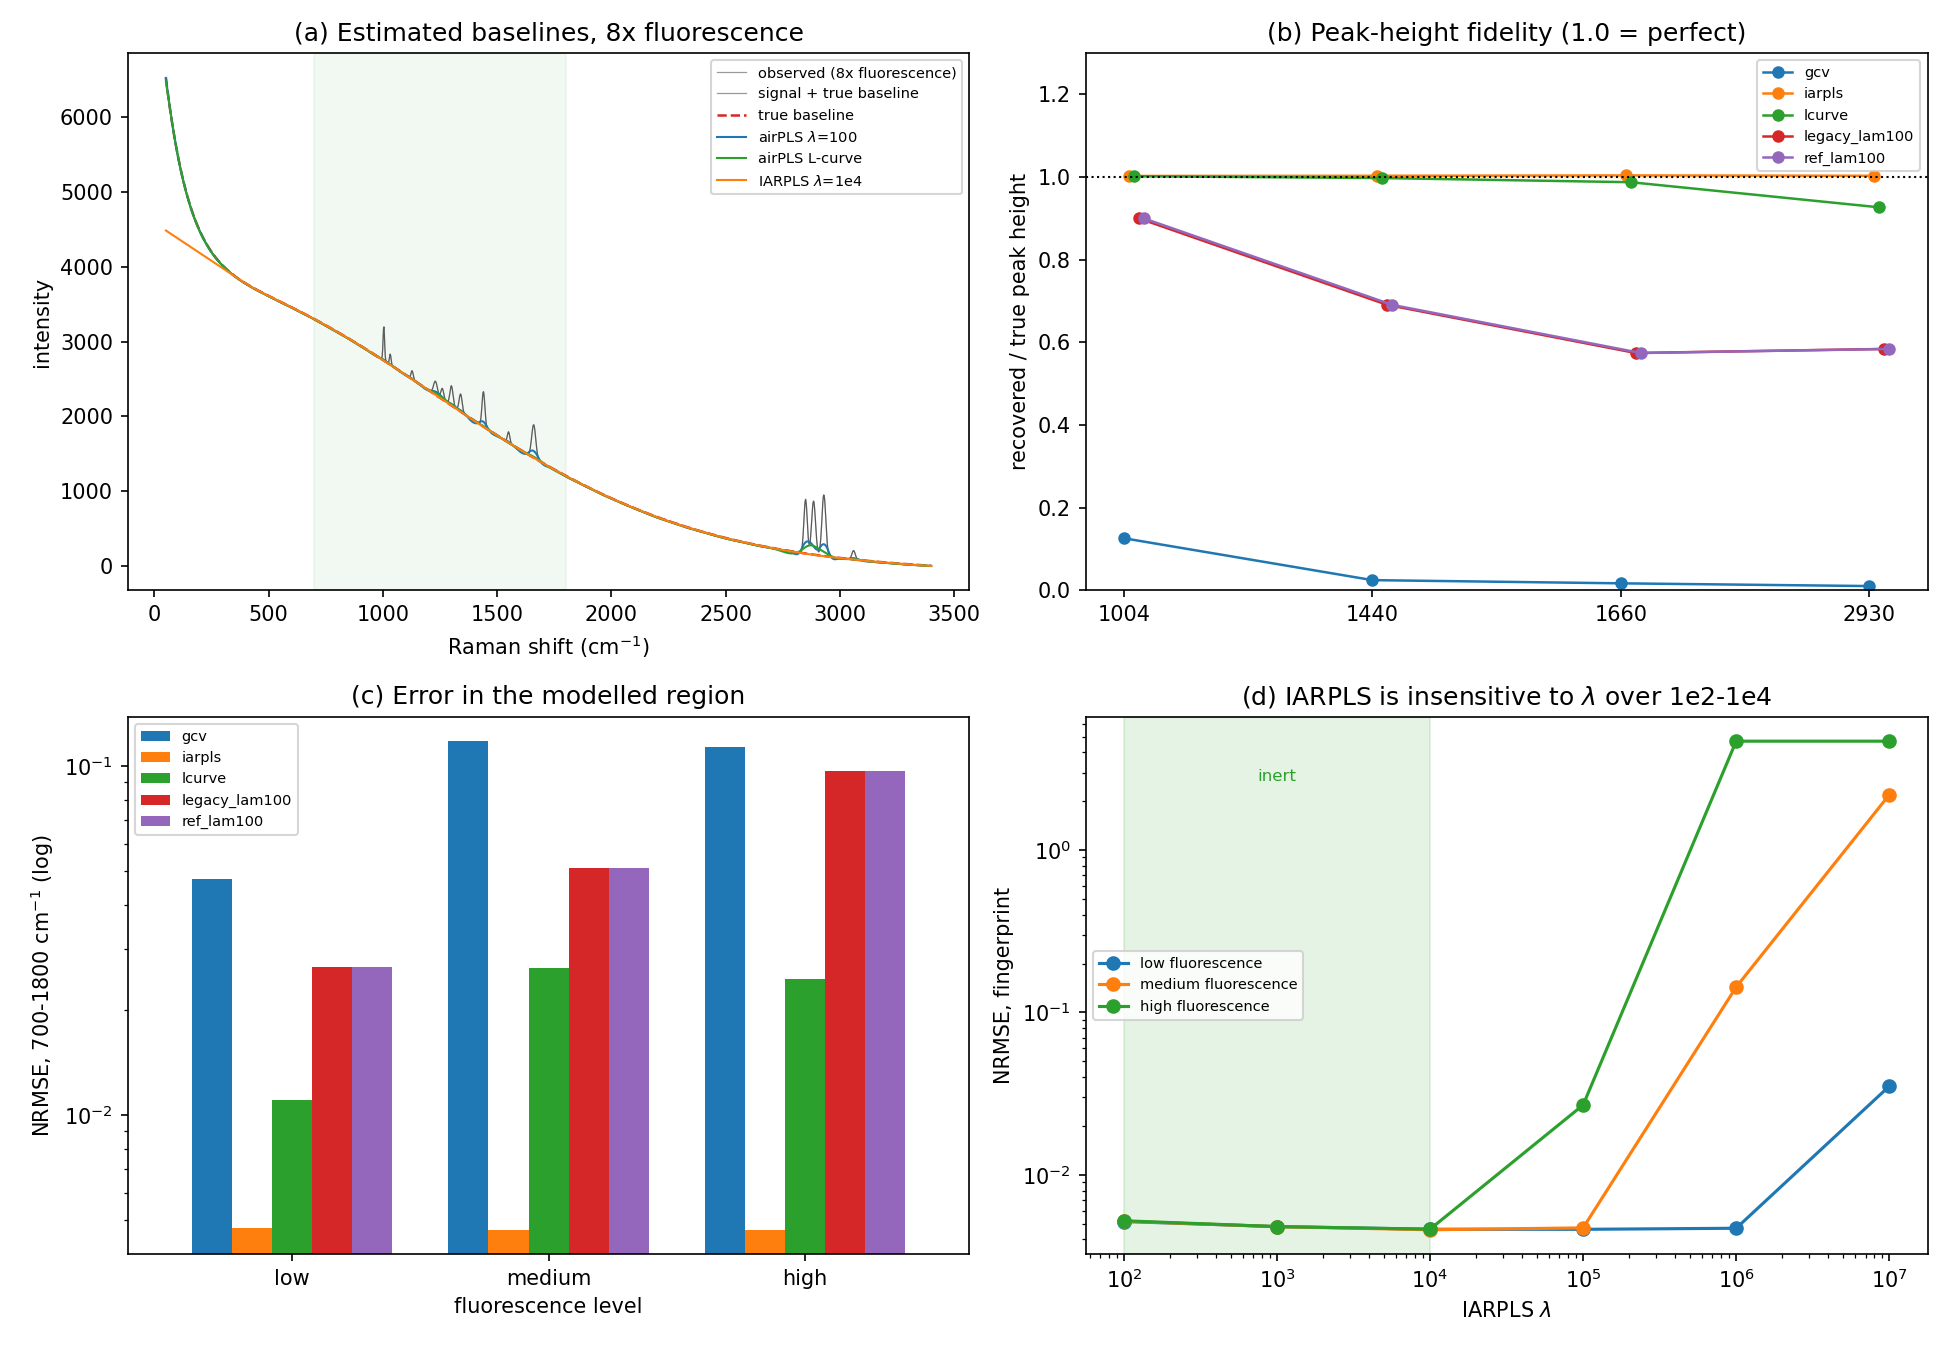

In [10]:
from IPython.display import Image, display
p = RESULTS / "stage0_baseline_study.png"
display(Image(filename=str(p))) if p.exists() else print(f"missing: {p}")

---
## 9. Real spectra: the invariance test in full

The invariance arm needs the raw cubes (`data/raw/`), which are not distributed with the
repository. If they are present this reruns the test on real tissue; otherwise the committed
results in §8 stand.

The test needs **no ground truth**: correct a real spectrum with and without added
fluorescence and compare peak heights. A corrector invariant to baseline gives the same
answer either way. Because there is no reference spectrum involved, the metric cannot be
biased by how that reference was constructed.

In [11]:
if not HAVE_RAW:
    print("data/raw/ not present - skipping (see the committed results in section 8).")
else:
    from scipy.ndimage import median_filter
    from stage0_baseline_study import load_real_spectra, invariance_score
    pool = load_real_spectra(6, np.random.default_rng(0), sorted((ROOT/"data"/"raw").glob("LGm-*/*.npy"))[:2])
    print(f"loaded {len(pool)} real spectra (3x3 spatial median filtered, as in production)\n")
    rows = []
    for k, y in enumerate(pool):
        r = np.random.default_rng(2000 + k)
        sc = max(np.ptp(y[m_fp]), 1e-12)
        extra = synthetic_baseline(wn, r, amplitude=8 * sc)
        for name, fn in [("airPLS lambda=100", lambda a: correct(a, lam=100.0, endpoint="legacy", clip_negative=False)["corrected"]),
                         ("IARPLS",            lambda a: correct_iarpls(a, wn, clip_negative=False)["corrected"])]:
            rows.append({"method": name, **invariance_score(wn, fn(y), fn(y + extra))})
    print("Peak-height drift on real spectra, 8x added fluorescence (0 = invariant)\n")
    print(pd.DataFrame(rows).groupby("method")[["drift_mean","drift_nrmse_fingerprint"]].median().round(4).to_string())

loaded 6 real spectra (3x3 spatial median filtered, as in production)

Peak-height drift on real spectra, 8x added fluorescence (0 = invariant)

                   drift_mean  drift_nrmse_fingerprint
method                                                
IARPLS                 0.0018                   0.0005
airPLS lambda=100      0.3227                   0.1493


---
## 10. Conclusion

| | verdict |
|---|---|
| **GCV** | Rejected. Pins at the grid floor; its i.i.d.-residual assumption does not hold here. |
| **L-curve** | Works (0% edge pinning, sensible λ), but unnecessary — and still bounded by airPLS. |
| **airPLS λ=100** (current) | Suppresses broad bands by up to 43% and lets peak heights drift 16–55% with fluorescence. |
| **IARPLS λ=1e4** | **Adopted.** Beats the airPLS oracle, λ-inert over 10²–10⁴, verified pure, ~25× cheaper. Crop below 300 cm⁻¹. |

The production entry point is `src.preprocessing.baseline.correct_iarpls`. It is wired into
the export during Stage 1, which rewrites `src/data/preprocessing.py`.

Full write-up: [`docs/stage0_findings.md`](../docs/stage0_findings.md).
Plan and stage tracker: [`docs/MIL_REFRAME_PLAN.md`](../docs/MIL_REFRAME_PLAN.md).